# Parallel AEQGA: Usage Guide

This notebook demonstrates one coordinated optimization with **complete parallel
subpopulations**. The public size arguments are `active_qubits` and
`parallel_circuits`. Every generation selects elites from the combined population
and distributes them across the subpopulations.

The runnable example fits three coefficients of a quadratic to generated data.
It needs no external dataset, account, or quantum hardware. Quantum operations
run in the local, ideal Qiskit Aer simulator; fitness evaluation and selection
run classically.

Keep these four files together:

| File | Responsibility |
|---|---|
| `AEQGA_Parallel_Usage.ipynb` | This executable English guide |
| `aeqga.py` | Public class, complete subpopulations, global selection, and records |
| `aeqga_legacy.py` | Inherited prediction, objective, quantum gates, decoding, and plotting |
| `aeqga_parallel.py` | Circuit packing, count marginalization, and layout helpers |

`aeqga_legacy.py` is a required dependency of this implementation. Import the
public class from **`aeqga.py`**, not from the legacy module.


## 1. Set up the environment

Use a Python **3.11** environment. The numerical stack used to check this bundle is:

```text
numpy==2.0.1
scipy==1.17.1
matplotlib==3.10.8
qiskit==2.3.0
qiskit-aer==0.17.2
```

Install the dependencies and a notebook interface in that environment:

```sh
python -m pip install numpy==2.0.1 scipy==1.17.1 matplotlib==3.10.8 qiskit==2.3.0 qiskit-aer==0.17.2
python -m pip install jupyterlab ipykernel==6.29.5
python -m jupyter lab
```

Open this notebook, select the environment's Python kernel, and use **Restart
Kernel and Run All Cells**. Launch Jupyter from the four-file directory or its
parent repository. The first cell locates that directory and checks the imports
so the repository's separate `aeqga/` package cannot silently replace these files.

Installation is not performed automatically by any notebook cell. Generated
results are written under `notebook_output/` inside the four-file directory.


In [1]:
from pathlib import Path
import importlib.metadata
import inspect
import platform
import sys
import csv
import gzip
import json

NOTEBOOK_NAME = "AEQGA_Parallel_Usage.ipynb"
REQUIRED_FILES = (NOTEBOOK_NAME, "aeqga.py", "aeqga_legacy.py", "aeqga_parallel.py")
search_dirs = (Path.cwd(), Path.cwd() / "parallel_aeqga", Path.cwd().parent / "parallel_aeqga")
SOURCE_DIR = next((folder.resolve() for folder in search_dirs
                   if all((folder / name).is_file() for name in REQUIRED_FILES)), None)
if SOURCE_DIR is None:
    raise FileNotFoundError("Start Jupyter in the four-file directory or its parent repository.")

for module_name in ("aeqga", "aeqga_legacy", "aeqga_parallel"):
    loaded = sys.modules.get(module_name)
    if loaded is not None and Path(getattr(loaded, "__file__", "")).resolve() != SOURCE_DIR / f"{module_name}.py":
        raise RuntimeError("A different AEQGA module is loaded. Restart the kernel, then Run All.")
sys.path.insert(0, str(SOURCE_DIR))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display
from qiskit import qpy
from aeqga import AEQGA

assert Path(inspect.getfile(AEQGA)).resolve() == SOURCE_DIR / "aeqga.py"
OUTPUT = SOURCE_DIR / "notebook_output"
OUTPUT.mkdir(exist_ok=True)
versions = {name: importlib.metadata.version(name)
            for name in ("numpy", "scipy", "matplotlib", "qiskit", "qiskit-aer")}
print("Python:", platform.python_version())
print("Source directory:", SOURCE_DIR.name)
print(json.dumps(versions, indent=2))


Python: 3.11.14
Source directory: parallel_aeqga
{
  "numpy": "2.0.1",
  "scipy": "1.17.1",
  "matplotlib": "3.10.8",
  "qiskit": "2.3.0",
  "qiskit-aer": "0.17.2"
}


## 2. Translate the qubit budget into population sizes

For `A = active_qubits` and `K = parallel_circuits`:

\[
q=\lfloor A/K\rfloor,\qquad N=2^q,\qquad
N_{\mathrm{total}}=K N.
\]

Each complete subpopulation circuit uses `q` qubits. The actual allocation is
`K*q` qubits; the remainder `A % K` is discarded. Each candidate is a **complete
parameter vector**, not one coefficient.

The default composition **within every group** is `N/4` elites, `N/4` local
offspring, and `N/2` random-origin global offspring. Increasing `shots` changes
the measurement sample size, not the number of candidate vectors.

The following table only calculates budgets; it does not run the larger circuits.


In [2]:
table = ["| Requested qubits | Circuits | Qubits/group | Used | Discarded | Candidates/group | Total candidates |",
         "|---:|---:|---:|---:|---:|---:|---:|"]
for active, groups in ((7, 2), (13, 3), (19, 3), (150, 30), (151, 25)):
    q = active // groups
    n = 2 ** q
    table.append(f"| {active} | {groups} | {q} | {q*groups} | {active % groups} | {n} | {n*groups} |")
display(Markdown("\n".join(table)))


| Requested qubits | Circuits | Qubits/group | Used | Discarded | Candidates/group | Total candidates |
|---:|---:|---:|---:|---:|---:|---:|
| 7 | 2 | 3 | 6 | 1 | 8 | 16 |
| 13 | 3 | 4 | 12 | 1 | 16 | 48 |
| 19 | 3 | 6 | 18 | 1 | 64 | 192 |
| 150 | 30 | 5 | 150 | 0 | 32 | 960 |
| 151 | 25 | 6 | 150 | 1 | 64 | 1600 |

## 3. Define the data and model

This example uses

\[
f(x; a,b,c)=a x^2+b x+c,\qquad
\chi^2=\sum_i\left[\frac{f(x_i;p)-y_i}{\sigma_i}\right]^2.
\]

With `vectorized=False` (the default), the function receives one sample's
features as a list and one candidate's parameters as a list. It returns one
real scalar. A scalar `sigma` is shared by all samples; a vector can provide
individual uncertainties. The generated coefficients below are only used to
make the example data, not to initialize or select optimizer candidates.


In [3]:
PARAMETER_NAMES = ["a", "b", "c"]
TRUE_PARAMETERS = np.array([1.2, -0.7, 0.35])
sigma = 0.08
x = np.linspace(-1.0, 1.0, 41)
data_rng = np.random.default_rng(2026)

def quadratic(x_list, p_list):
    value = x_list[0]
    a, b, c = p_list
    return a * value**2 + b * value + c

y_without_noise = np.array([quadratic([value], TRUE_PARAMETERS) for value in x])
y = y_without_noise + data_rng.normal(0.0, sigma, size=x.size)
print(f"Samples: {x.size}; parameters: {PARAMETER_NAMES}; sigma: {sigma}")


Samples: 41; parameters: ['a', 'b', 'c']; sigma: 0.08


## 4. Create the optimizer

The example allocates 7 requested qubits to 2 circuits: 3 qubits per circuit,
6 qubits used, and 1 discarded. Each group has 8 candidates (2 elite, 2 local,
4 global), for a combined population of 16. This small default keeps the
complete tutorial practical to run locally; larger budgets are arithmetic examples,
not simulation timing benchmarks.

The two circuits participate in **one training run**. They are not two
independent optimization runs: the global elite pool connects them every generation.

| Argument | Meaning |
|---|---|
| `function`, `p`, `bounds` | Model, initial parameter vector, and one finite `(lower, upper)` interval per parameter |
| `active_qubits`, `parallel_circuits` | Requested total qubits and number of complete simultaneous subpopulations |
| `elite_count`, `local_count`, `random_count` | Optional counts **per group**; defaults are `N//4`, `N//4`, `N//2` |
| `shots` | Repetitions of each complete circuit; every stage yields this many measurements |
| `crossover_probability`, `mutation_probability` | Probabilities of applying the CRy pair and Rx operation at each stage; defaults are 0.5 |
| `local_padding`, `min_local_width` | Local interval expansion and minimum width relative to the parameter's global range; defaults are 0.5 and 0.01 |
| `seed` | Controls candidate initialization, gate choices, and simulator sampling |
| `vectorized` | If true, the function receives the entire input batch and returns one prediction per sample |
| `max_total_candidates` | Allocation guard on `K * 2**q`; default 65536 |

All count parameters must sum to `N`. Elites must be positive; local/global
counts can be zero. Unspecified counts retain their defaults. Each group needs
at least 3 qubits under the current implementation.

`population_size` and `max_parallel_qubits` are no longer constructor arguments.
The derived `model.population_size` attribute is the **total across all groups**.


In [4]:
ACTIVE_QUBITS = 7
PARALLEL_CIRCUITS = 2
GENERATIONS = 20
SHOTS = 64
SEED = 7
BOUNDS = [(-3.0, 3.0), (-3.0, 3.0), (-2.0, 2.0)]
INITIAL_PARAMETERS = [0.0, 0.0, 0.0]

model = AEQGA(
    quadratic,
    p=INITIAL_PARAMETERS,
    bounds=BOUNDS,
    active_qubits=ACTIVE_QUBITS,
    parallel_circuits=PARALLEL_CIRCUITS,
    shots=SHOTS,
    seed=SEED,
)
budget = {
    "requested_qubits": model.active_qubits,
    "qubits_per_circuit": model.qubits_per_circuit,
    "used_qubits": model.used_active_qubits,
    "discarded_qubits": model.discarded_qubits,
    "parallel_circuits": model.parallel_circuits,
    "candidates_per_circuit": model.population_per_circuit,
    "total_candidates": model.population_size,
    "per_group_elite_local_global": [model.elite_count, model.local_count, model.random_count],
}
print(json.dumps(budget, indent=2))


{
  "requested_qubits": 7,
  "qubits_per_circuit": 3,
  "used_qubits": 6,
  "discarded_qubits": 1,
  "parallel_circuits": 2,
  "candidates_per_circuit": 8,
  "total_candidates": 16,
  "per_group_elite_local_global": [
    2,
    2,
    4
  ]
}


## 5. Train and read the global best

The initial population is generation **0**. `generations=20` then performs 20
updates and records 21 populations. The initial `p` is placed in the first
position of every group; other initial candidates use separate random streams.

Each update selects elites globally, generates the local/global offspring, and
evaluates all new complete parameter vectors. Elite objective values are reused.
`model.p` and `model.loss_` refer to the current **global best**, across all groups.

Without `sigma` or `covariance`, the objective is SSE. Providing either selects
chi-square; do not provide both. `target_loss` can stop training early. Repeating
`train` on the same object resets its histories and initializes around the object's
current `p`; create a fresh object to repeat the original initialization.


In [5]:
model.train(x.tolist(), y.tolist(), generations=GENERATIONS, sigma=sigma)
best_prediction = np.asarray(model.predict(x.tolist()))
independent_chi2 = float(np.sum(((best_prediction - y) / sigma) ** 2))
assert np.isclose(model.loss_, independent_chi2, rtol=1e-12, atol=1e-10)

print("Global best parameters:", dict(zip(PARAMETER_NAMES, model.p)))
print(f"Chi-square: {model.loss_:.6f}")
print("Completed updates:", model.n_generations_)
print("Recorded populations:", len(model.history_))
print("Fitness evaluations:", model.n_evaluations_)
print("Final subpopulation array shape:", model.subpopulations_.shape)


Global best parameters: {'a': 1.6339399493786626, 'b': -0.21645026277361892, 'c': 0.3118323340151847}
Chi-square: 707.153994
Completed updates: 20
Recorded populations: 21
Fitness evaluations: 256
Final subpopulation array shape: (2, 8, 3)


## 6. Inspect the global elite allocation

Every generation, all `K*N` candidates are sorted by loss using a stable sort.
The best `K*elite_count` indices are selected and distributed in rank order:
rank 0 to group 0, rank 1 to group 1, and so on, wrapping around the groups.
Each group then uses its assigned elites to determine its local search interval.

Selection normally uses distinct candidate indices; distinct indices may contain
equal parameter vectors. If too few candidates have finite loss, valid elites
are copied to fill the required slots. There is no periodic migration schedule.

The following output shows the actual transfer from generation 0 to generation 1.
Source group and individual IDs are zero-based.


In [6]:
transfer = model.selection_history_[0]
table = ["| Destination group | Global ranks received (zero-based) | Source groups | Source individuals |",
         "|---:|---|---|---|"]
for assignment in transfer["assignments"]:
    group = assignment["circuit_index"]
    ranks = list(range(group, model.parallel_circuits * model.elite_count, model.parallel_circuits))
    table.append(f"| {group} | {ranks} | {assignment['source_circuits']} | {assignment['source_individuals']} |")
display(Markdown("\n".join(table)))
print("Selection policy:", transfer["policy"])


| Destination group | Global ranks received (zero-based) | Source groups | Source individuals |
|---:|---|---|---|
| 0 | [0, 2] | [0, 0] | [6, 0] |
| 1 | [1, 3] | [0, 1] | [3, 0] |

Selection policy: global_elites_round_robin


## 7. Plot the training result and trajectory

The parameter trajectories follow the best **complete individual** at each
generation. Components can move when another individual becomes best; the
global best chi-square does not increase because elites are retained.

The data plot also includes a classical weighted least-squares reference,
computed **after** AEQGA training. It is an objective reference for this quadratic
example and is never supplied to the optimizer. A finite AEQGA run is not
guaranteed to reach it. Neither the trajectory nor the spread of candidates is
a posterior distribution or a parameter uncertainty interval.


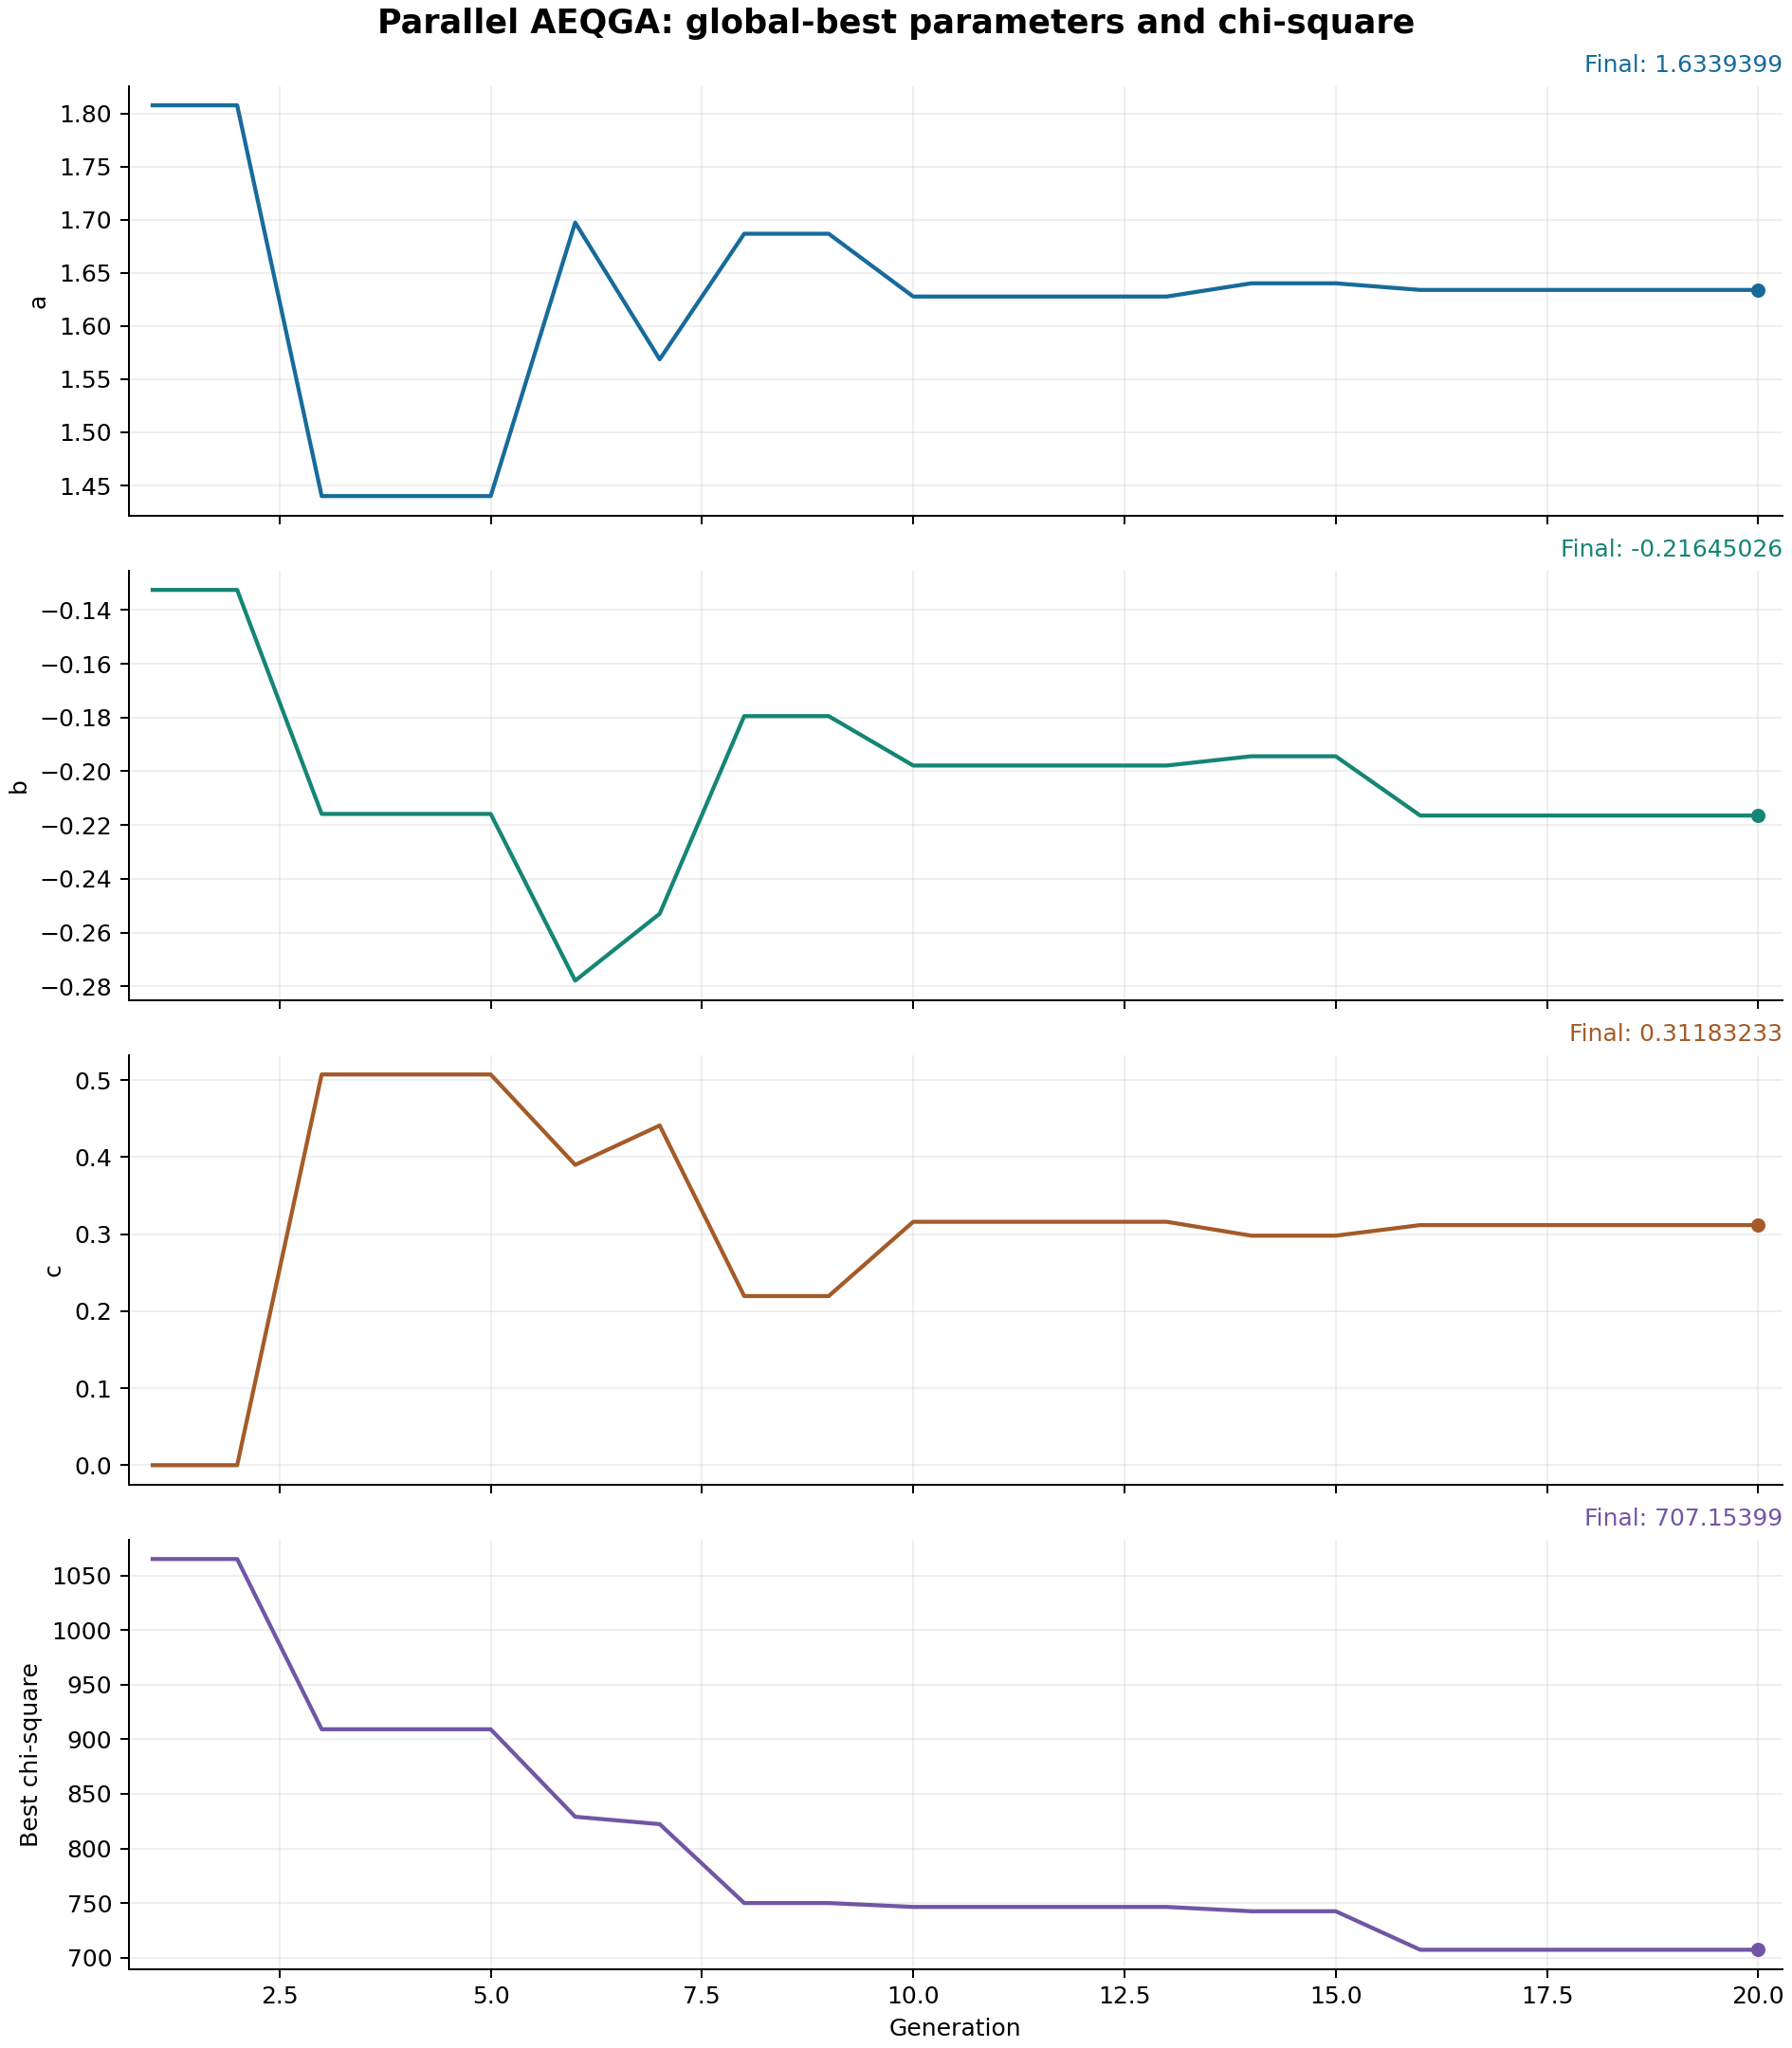

In [7]:
history_path = model.export_history_plot(
    OUTPUT / "training_history.png",
    parameter_names=PARAMETER_NAMES,
    title="Parallel AEQGA: global-best parameters and chi-square",
    loss_label="Best chi-square",
)
display(Image(filename=str(history_path)))


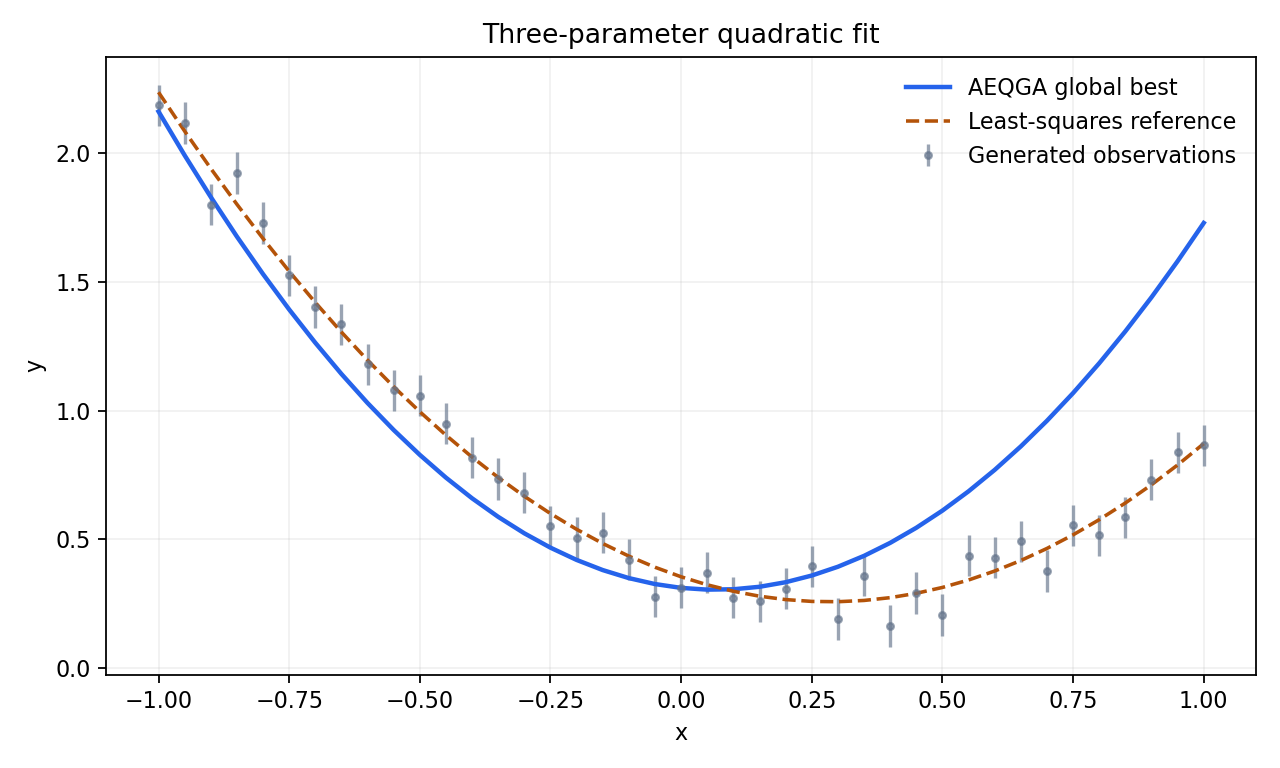

AEQGA chi-square: 707.153994
Reference chi-square: 26.093260
Difference: 681.060734


In [8]:
design = np.column_stack((x**2, x, np.ones_like(x)))
reference_parameters = np.linalg.lstsq(design / sigma, y / sigma, rcond=None)[0]
reference_chi2 = float(np.sum(((design @ reference_parameters - y) / sigma) ** 2))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.errorbar(x, y, yerr=sigma, fmt="o", markersize=3, alpha=0.65, color="#64748b", label="Generated observations")
ax.plot(x, best_prediction, linewidth=2, color="#2563eb", label="AEQGA global best")
ax.plot(x, design @ reference_parameters, "--", linewidth=1.6, color="#b45309", label="Least-squares reference")
ax.set(xlabel="x", ylabel="y", title="Three-parameter quadratic fit")
ax.legend(frameon=False)
ax.grid(alpha=0.18)
fig.tight_layout()
fit_plot_path = OUTPUT / "data_and_fit.png"
fig.savefig(fit_plot_path, dpi=160)
plt.close(fig)
display(Image(filename=str(fit_plot_path)))
print(f"AEQGA chi-square: {model.loss_:.6f}")
print(f"Reference chi-square: {reference_chi2:.6f}")
print(f"Difference: {model.loss_ - reference_chi2:.6f}")


## 8. Export every candidate and its objective

`history_` contains all candidates, including generation 0. Each entry stores the
complete parameter vector and objective, group ID, individual ID, and origin
(`initial`, `elite`, `local`, or `global`). For weighted training, `chi2` also
contains the chi-square. Per-generation records include each group's best and
the global elite assignment.

The CSV has one row per candidate per recorded generation. With this example's
settings it contains `21 * 16 = 336` rows. Elite rows remain in the history even
when their objective was carried forward rather than recomputed.

The compressed JSONL files retain the richer training and execution records.
Each line is one generation. The QPY file contains the **last executed** packed
circuit, not all generations. History files are records, not restart checkpoints;
the class does not expose a resume-from-history method.


In [9]:
population_path = model.export_population_history(
    OUTPUT / "population_history.csv", parameter_names=PARAMETER_NAMES)
for filename, records in (
    ("training_history.jsonl.gz", model.history_),
    ("execution_history.jsonl.gz", model.execution_history_),
):
    with gzip.open(OUTPUT / filename, "wt", encoding="utf-8") as stream:
        for record in records:
            stream.write(json.dumps(record) + "\n")
with (OUTPUT / "last_generation.qpy").open("wb") as stream:
    qpy.dump(model.execution_circuits_, stream)

with population_path.open(newline="", encoding="utf-8") as stream:
    candidate_rows = list(csv.DictReader(stream))
expected_rows = len(model.history_) * model.population_size
assert len(candidate_rows) == expected_rows
print("Candidate rows:", len(candidate_rows))
print("CSV columns:", list(candidate_rows[0]))

table = ["| Generation | Group | Individual | Origin | a | b | c | Chi-square |",
         "|---:|---:|---:|---|---:|---:|---:|---:|"]
for row in candidate_rows[-8:]:
    table.append(f"| {row['generation']} | {row['circuit_index']} | {row['individual']} | {row['origin']} | "
                 f"{float(row['a']):.4f} | {float(row['b']):.4f} | {float(row['c']):.4f} | {float(row['chi2']):.4f} |")
display(Markdown("\n".join(table)))


Candidate rows: 336
CSV columns: ['generation', 'circuit_index', 'individual', 'origin', 'a', 'b', 'c', 'chi2']


| Generation | Group | Individual | Origin | a | b | c | Chi-square |
|---:|---:|---:|---|---:|---:|---:|---:|
| 20 | 1 | 0 | elite | 1.6685 | -0.1926 | 0.2368 | 715.4542 |
| 20 | 1 | 1 | elite | 1.6351 | -0.2073 | 0.3179 | 736.3318 |
| 20 | 1 | 2 | local | 1.6668 | -0.1835 | 0.2604 | 751.5685 |
| 20 | 1 | 3 | local | 1.6518 | -0.1675 | 0.2604 | 774.7973 |
| 20 | 1 | 4 | global | 3.0000 | -1.0000 | -1.3750 | 10032.4195 |
| 20 | 1 | 5 | global | -2.8235 | 3.0000 | -1.7500 | 119638.3738 |
| 20 | 1 | 6 | global | -2.5606 | 0.0000 | 2.0000 | 10624.8311 |
| 20 | 1 | 7 | global | -0.3529 | 2.0000 | 1.1250 | 17999.8011 |

## 9. Understand the packed circuits and measurement records

Each group reuses its assigned `q` qubits across successive parameter/branch
stages. Three parameters and two nonempty offspring branches produce **six
stages per complete circuit**. Each stage resets the qubits, prepares amplitudes,
applies the selected gates, and measures into a fresh segment of classical bits.

All stages use the full `q`-qubit register. Branch values are padded with zeros
to `2**q` amplitudes; decoding keeps only that branch's requested number of rows.
Parameter columns are joined by candidate row index to form complete vectors.
Elites are retained classically. With zero local or global candidates, that
branch's stages are omitted; an all-elite population executes no quantum circuit.

The `K` complete circuits are packed onto disjoint qubits and executed together
once per generation in this example. A shot includes all stages. The sparse
joint counts are split by group and then by stage, and each stage's counts sum
to `shots`. No array of size `2**total_classical_bits` is created.

For these settings, a packed circuit has 6 active qubits and 36 classical bits
(`2 groups * 6 stages * 3 bits`). Reusing qubits adds circuit depth and
mid-circuit measurement/reset operations. This local ideal simulation does not
establish hardware execution time, routing cost, or noise tolerance.


In [10]:
last_execution = model.execution_history_[-1]
packed = last_execution["executions"][0]
stages = last_execution["stage_measurements"]
print("Complete subpopulation circuits executed:", model.quantum_circuits_)
print("Parameter/branch stages executed:", model.quantum_stages_)
print("Packed circuit executions:", model.executed_circuits_)
print("Last packed active qubits:", packed["active_qubits"])
print("Last packed classical bits:", model.execution_circuits_[0].num_clbits)
print("Recorded stages in last generation:", len(stages))
print("First stage identity:", {key: stages[0][key] for key in
      ("subpopulation_index", "stage_index", "branch", "parameter_index", "candidate_count")})
print("First stage measurement count:", sum(stages[0]["counts"].values()))


Complete subpopulation circuits executed: 40
Parameter/branch stages executed: 240
Packed circuit executions: 20
Last packed active qubits: 6
Last packed classical bits: 36
Recorded stages in last generation: 12
First stage identity: {'subpopulation_index': 0, 'stage_index': 0, 'branch': 'local', 'parameter_index': 0, 'candidate_count': 2}
First stage measurement count: 64


## 10. Check the completed run

These checks verify the requested allocation, complete candidate records,
per-group proportions, global elite transfer, and measurement totals. The final
chi-square was also recomputed from the model's predictions in section 5.

The summary file records the run settings, best parameters, software versions,
and checks. Outputs created by this notebook are not included in the original
four-file ZIP; the saved notebook itself contains the example's executed results.


In [11]:
expected_q = ACTIVE_QUBITS // PARALLEL_CIRCUITS
expected_n = 2 ** expected_q
expected_active = expected_q * PARALLEL_CIRCUITS
assert model.used_active_qubits == expected_active
assert model.discarded_qubits == ACTIVE_QUBITS % PARALLEL_CIRCUITS
assert model.subpopulations_.shape == (PARALLEL_CIRCUITS, expected_n, len(PARAMETER_NAMES))
assert model.n_generations_ == GENERATIONS
assert len(model.history_) == GENERATIONS + 1
assert np.all(np.diff([entry["loss"] for entry in model.history_]) <= 1e-10)

for entry in model.history_:
    assert len(entry["population"]) == model.population_size
    assert all(len(candidate["p"]) == len(PARAMETER_NAMES) for candidate in entry["population"])
    if entry["generation"]:
        for group in range(model.parallel_circuits):
            members = [candidate for candidate in entry["population"] if candidate["circuit_index"] == group]
            assert [sum(candidate["origin"] == label for candidate in members)
                    for label in ("elite", "local", "global")] == [model.elite_count, model.local_count, model.random_count]

for previous, current in zip(model.history_, model.history_[1:]):
    elite_total = model.parallel_circuits * model.elite_count
    ranked = np.argsort([candidate["loss"] for candidate in previous["population"]], kind="stable")[:elite_total].tolist()
    assert current["elite_selection"]["global_elite_indices"] == ranked
    for group in range(model.parallel_circuits):
        start = group * model.population_per_circuit
        assigned = current["population"][start:start + model.elite_count]
        assert [candidate["p"] for candidate in assigned] == [previous["population"][index]["p"] for index in ranked[group::model.parallel_circuits]]

for execution in model.execution_history_:
    assert len(execution["executions"]) == 1
    assert execution["executions"][0]["active_qubits"] == expected_active
    branches = int(model.local_count > 0) + int(model.random_count > 0)
    assert len(execution["stage_measurements"]) == PARALLEL_CIRCUITS * len(PARAMETER_NAMES) * branches
    assert all(sum(stage["counts"].values()) == SHOTS for stage in execution["stage_measurements"])
assert model.executed_circuits_ == GENERATIONS

summary = {
    "configuration": {**budget, "generations": GENERATIONS, "shots": SHOTS, "seed": SEED,
                      "data_seed": 2026, "bounds": BOUNDS, "initial_parameters": INITIAL_PARAMETERS},
    "selection_policy": "global_elites_round_robin",
    "parameter_names": PARAMETER_NAMES,
    "best_parameters": model.p,
    "chi2": model.loss_,
    "independent_chi2": independent_chi2,
    "classical_reference_chi2": reference_chi2,
    "candidate_history_rows": len(candidate_rows),
    "packed_executions": model.executed_circuits_,
    "versions": versions,
    "checks": "passed",
}
(OUTPUT / "run_summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print("All checks passed.")
print("Output directory:", OUTPUT.name)
for path in sorted(OUTPUT.iterdir()):
    if path.is_file():
        print(f"  {path.name} ({path.stat().st_size:,} bytes)")


All checks passed.
Output directory: notebook_output
  data_and_fit.png (90,978 bytes)
  execution_history.jsonl.gz (13,092 bytes)
  last_generation.qpy (9,907 bytes)
  population_history.csv (27,848 bytes)
  run_summary.json (1,203 bytes)
  training_history.jsonl.gz (11,236 bytes)
  training_history.png (186,576 bytes)


## 11. Adapt the example

### Change the model or use real data

Replace `quadratic`, `x`, `y`, `p`, and `bounds`. Give one bound pair per fitted
parameter. For three cosmological parameters, a candidate might be
`[H0, Omega_m, M]`; the model function must compute the corresponding predictions
for the selected observations. This example's quadratic data are not a
cosmological likelihood.

For a model that evaluates an entire input batch, set `vectorized=True`:

```python
def quadratic_batch(x_batch, p):
    values = np.asarray(x_batch)
    values = values if values.ndim == 1 else values[:, 0]
    return p[0] * values**2 + p[1] * values + p[2]

batch_model = AEQGA(
    quadratic_batch, p=[0, 0, 0], bounds=BOUNDS,
    active_qubits=7, parallel_circuits=2, vectorized=True, seed=7,
)
```

For correlated observations, use a finite symmetric positive-definite covariance
matrix in observation order instead of `sigma`:

```python
covariance = np.diag(np.full(len(y), sigma**2))  # independent-error illustration
batch_model.train(x.tolist(), y.tolist(), covariance=covariance, generations=20)
```

### Change the qubit budget

Set `active_qubits` and `parallel_circuits` on a **new instance**. For example,
151 requested qubits and 25 circuits give 6 qubits and 64 candidates per group,
1600 candidates in total, and one unused qubit. All groups share the same three
candidate counts. Do not change derived size attributes after construction.

An equal qubit total with fewer circuits can produce many more candidates:
150 qubits divided into 5 circuits implies `5 * 2**30` complete candidates.
The default `max_total_candidates=65536` guard rejects that allocation before
creating candidate arrays. Raising the guard requires budgeting state preparation,
classical objective evaluation, and full-history storage as well as simulation.

### Repeat a run

Create a new instance with the original `p`, settings, and seed. Reproducibility
also depends on the same software environment and execution configuration.
Changing the number of groups or shot count changes the sampling process.

### IBM noise and hardware

This four-file bundle provides local **ideal** simulation. IBM noise adapters,
calibration snapshots, real-data runners, and hardware submission interfaces are
outside its scope. Adding a device name to this class does not select an IBM
computer. Hardware use requires an appropriate execution adapter and checks for
physical layout, native gates, and the sequential measurement/reset stages.

### Common errors

| Symptom | Check |
|---|---|
| A local AEQGA module cannot be imported | Keep the four files together and launch Jupyter in their directory or parent repository |
| A different AEQGA module is already loaded | Restart the kernel and run from the first cell |
| `active_qubits // parallel_circuits` is too small | Use at least 3 qubits per group |
| Candidate allocation exceeds the limit | Reduce the per-group qubit count or explicitly budget a larger limit |
| Counts do not sum to the population | Per-group elite/local/global counts must sum to `2**q` |
| Model prediction has the wrong shape | Return one scalar per sample, or one value per sample with `vectorized=True` |
| All initial losses are non-finite | Check the model's numerical domain, inputs, and parameter bounds |
